# 2 · Train and validate: task, metric, baselines, models, selection (all before the test set)
Notebooks: [1 data](1_data.ipynb) · [2 train & validate](2_train_validate.ipynb) · [3 test](3_test.ipynb) · [4 results for the CISO](4_results_ciso.ipynb) · [5 CISO tool](5_ciso_tool.ipynb) · detailed appendices in `appendix/`.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl")); os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
TAB, FIG = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA, VIOLET, RED, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#d64545", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
def T(name, **kw): return pd.read_csv(TAB / f"{name}.csv", **kw)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
pt = lambda s: float(str(s).split()[0])
HEAD, ALT, EPSS7 = "gradient boosting (headline)", "late fusion (alternative)", 'EPSS (first score, <=7 d after pub)'

## 2.1 Task, splits, metric
* **Supervised** binary classification on publication-day information only; the output is used as a **monthly ranking**.
* **Split by date:** train 2022-01 → 2024-06, validation 2024-07 → 2024-12, **test 2025-01 → 2026-08-20 (opened once,
  notebook 3)**; walk-forward folds 2022 → 2023 and 2022–23 → 2024-H1 inside dev.
* **recall@K per calendar month**: each month patch the top K; recall = exploited caught / all exploited.
  K = **110** = monthly capacity of the CVSS ≥ 9 (CNA) rule in train; K = **305** = the hindsight rule's capacity.
  Fixed before modelling; the full recall-vs-K curve is always shown.
* **Uncertainty:** paired within-month Poisson bootstrap (2,000) → 95% CIs. **Selection rule:** mean recall@110 over
  WF 2023, WF 2024-H1 and validation (never validation alone).

In [2]:
split = pd.DataFrame({"period": ["train", "validation", "test"], "dates": ["2022-01 -> 2024-06", "2024-07 -> 2024-12", "2025-01 -> 2026-08-20"],
                      "CVEs": [74268, 19574, 102561], "exploited": [251, 68, 294], "months": [30, 6, 20]})
split["rate %"] = (100 * split["exploited"] / split["CVEs"]).round(3); split["CVEs / month"] = (split["CVEs"] / split["months"]).round(0)
split["K=110 as % of a month"] = (100 * 110 / split["CVEs / month"]).round(1); display(split.set_index("period"))

,dates,CVEs,exploited,months,rate %,CVEs / month,K=110 as % of a month
period,,,,,,,
train,2022-01 -> 2024-06,74268,251,30,0.338,2476.0,4.4
validation,2024-07 -> 2024-12,19574,68,6,0.347,3262.0,3.4
test,2025-01 -> 2026-08-20,102561,294,20,0.287,5128.0,2.1


**Takeaway**: A date split is harder and honest: test months are twice as large as train months (5,128 vs 2,476 CVEs), so the fixed K = 110 covers 4.4% of a train month but only 2.1% of a test month.

## 2.2 Baselines: business rules on validation (day-0 information)

,type,rule patches/month,rule recall %,recall@110 % [95% CI],recall@305 % [95% CI],PR-AUC
method,,,,,,
random,benchmark,NaN,NaN,3.5,9.6,NaN
CVSS (CNA) ranking,benchmark,196.0,33.8,23.7 [13–33],38.3 [27–50],0.011
"phrase, then CVSS (CNA)",benchmark,197.0,38.2,28.1 [17–38],42.7 [31–55],0.069
generous CVSS (fallback) ranking,"benchmark (hindsight, upper bound)",313.0,41.2,15.1 [6–25],38.5 [27–51],0.011
CVSS>=7 (CNA) rule,benchmark,1089.0,64.7,= CVSS (CNA) ranking,= CVSS (CNA) ranking,NaN
preview: logistic regression (day-0 tabular),model preview (Phase 5),NaN,NaN,36.8,67.6,0.108


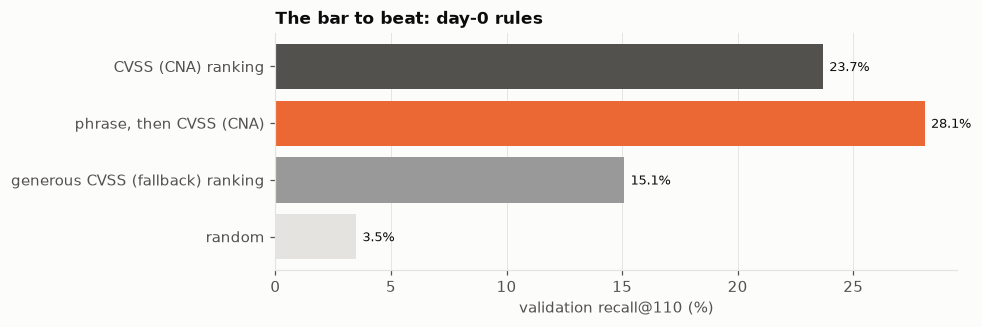

In [3]:
bv = T("04_val_comparison").set_index("method"); display(bv)
order = ["CVSS (CNA) ranking", "phrase, then CVSS (CNA)", "generous CVSS (fallback) ranking", "random"]
v = [pt(bv.loc[m, "recall@110 % [95% CI]"]) for m in order]
fig, ax = plt.subplots(figsize=(8, 2.8)); ax.barh(order, v, color=[INK2, ORANGE, "#999999", GRID]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
for i, x in enumerate(v): ax.annotate(f"{x:.1f}%", (x, i), xytext=(4, -3), textcoords="offset points", fontsize=8.5)
ax.set_xlabel("validation recall@110 (%)"); ax.set_title("The bar to beat: day-0 rules", loc="left"); save(fig, "2_01_baselines")

**Takeaway**: **The best rule a careful team could run today — 'exploitation phrase first, then CNA CVSS' — catches 28.1% [17–38] of exploited validation CVEs with 110 patches a month**; plain CVSS ranking 23.7%, random 3.5%. Hindsight CVSS (ADP-filled) does *not* help at K = 110 (15.1%).

## 2.3 Tabular ML vs deep learning on text
* **Supervised, hand-built features:** logistic regression and gradient boosting (scikit-learn HistGradientBoosting) on CNA
  CVSS, CNA, vendor, CWE, description length, day-0 exploitation phrase, vendor/product KEV history.
* **Pretrained (self-supervised) representations:** MiniLM / BGE sentence embeddings of the day-0 description (encoders
  pretrained on unlabeled text) + a supervised head (logistic regression or a small MLP, early stopping, 5 seeds).
* **Fine-tuned transformer:** MiniLM fine-tuned end-to-end on our labels (Apple GPU).
* **Combinations:** tabular + text MLP; boosting + out-of-fold text score; **late fusion** (mean of within-month ranks).

,learning,selection (3-period mean),worst period,val recall@110 [CI],val recall@305 [CI]
method,,,,,
gradient boosting,"supervised, tabular",47.4,39.7,47.1 [36–60],67.6 [57–79]
late fusion: boosting + text MLP,tabular + text (rank fusion),46.7,42.6,42.6 [30–55],64.7 [54–77]
boosting + OOF text score,tabular + text,45.3,42.1,42.6 [32–55],63.2 [51–74]
tabular + text MLP,tabular + text,44.8,38.8,38.2 [27–50],75.0 [63–84]
"text MLP (MiniLM, 5 seeds)",pretrained + supervised head,39.5,30.6,32.4 [20–43],50.0 [38–63]
text LR (MiniLM embeddings),pretrained + supervised head,39.2,23.5,23.5 [14–34],45.6 [33–58]
logistic regression,"supervised, tabular",37.8,28.9,30.9 [21–43],58.8 [46–70]
fine-tuned MiniLM (2 seeds),pretrained + supervised fine-tuning,34.6,26.5,25.0 [15–36],57.4 [44–68]
"phrase, then CVSS (CNA)",best day-0 rule,34.1,28.1,28.1 [17–38],42.7 [31–55]


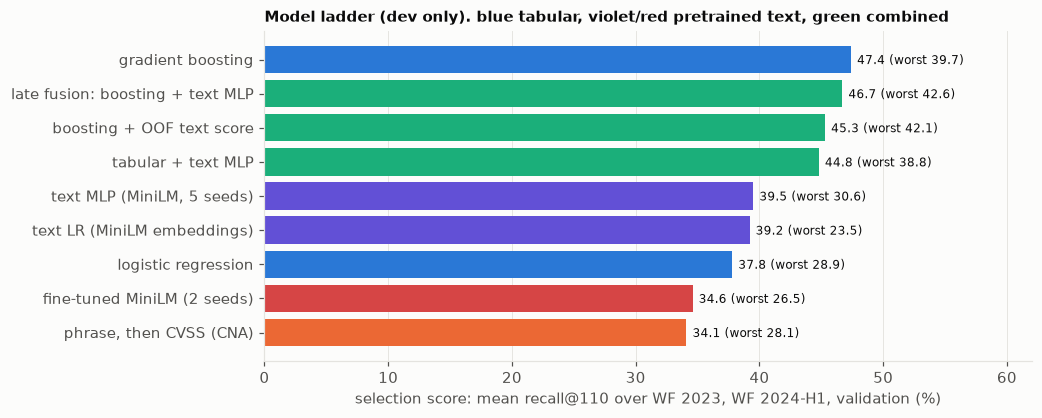

In [4]:
a5 = T("05a_comparison").set_index("method"); b5 = T("05b_comparison").set_index("method"); c5 = T("05c_comparison").set_index("method")
V110, V305 = "val recall@110 [CI] (ensemble for nets)", "val recall@305 [CI] (ensemble for nets)"
rows = [("phrase, then CVSS (CNA)", "best day-0 rule", b5.loc["phrase, then CVSS (CNA)"]), ("gradient boosting", "supervised, tabular", b5.loc["gradient boosting (05a)"]),
        ("text LR (MiniLM embeddings)", "pretrained + supervised head", b5.loc["text LR"]), ("text MLP (MiniLM, 5 seeds)", "pretrained + supervised head", b5.loc["text MLP (5 seeds)"]),
        ("tabular + text MLP", "tabular + text", b5.loc["(a) tabular+text MLP (5 seeds)"]), ("boosting + OOF text score", "tabular + text", b5.loc["(b) gradient boosting + OOF text score"]),
        ("late fusion: boosting + text MLP", "tabular + text (rank fusion)", b5.loc["(c) late fusion: gradient boosting + text MLP (5 seeds)"])]
out = [{"method": n, "learning": k, "selection (3-period mean)": r["selection (3-period mean)"], "worst period": r["worst period"], "val recall@110 [CI]": r[V110], "val recall@305 [CI]": r[V305]} for n, k, r in rows]
lr = a5.loc["logistic regression"]; lv = pt(lr["val recall@110 [CI]"])
out.append({"method": "logistic regression", "learning": "supervised, tabular", "selection (3-period mean)": round(np.mean([lr["WF 2023"], lr["WF 2024-H1"], lv]), 1),
            "worst period": min(lr["WF 2023"], lr["WF 2024-H1"], lv), "val recall@110 [CI]": lr["val recall@110 [CI]"], "val recall@305 [CI]": lr["val recall@305 [CI]"]})
ft = c5.loc["fine-tuned MiniLM (lr1e-5_full, 2 seeds)"]
out.append({"method": "fine-tuned MiniLM (2 seeds)", "learning": "pretrained + supervised fine-tuning", "selection (3-period mean)": ft["selection (3-period mean)"],
            "worst period": ft["worst period"], "val recall@110 [CI]": ft["val recall@110 [CI]"], "val recall@305 [CI]": ft["val recall@305 [CI]"]})
ladder = pd.DataFrame(out).set_index("method").sort_values("selection (3-period mean)", ascending=False); display(ladder)
col = {"best day-0 rule": ORANGE, "supervised, tabular": BLUE, "pretrained + supervised head": VIOLET, "pretrained + supervised fine-tuning": RED, "tabular + text": AQUA, "tabular + text (rank fusion)": AQUA}
lad = ladder.iloc[::-1]; fig, ax = plt.subplots(figsize=(9, 3.9))
ax.barh(lad.index, lad["selection (3-period mean)"], color=[col[k] for k in lad["learning"]])
for i, (s, w) in enumerate(zip(lad["selection (3-period mean)"], lad["worst period"])): ax.annotate(f"{s:.1f} (worst {w:.1f})", (s, i), xytext=(4, -3), textcoords="offset points", fontsize=8)
ax.set_xlim(0, 62); ax.grid(axis="y", visible=False); ax.set_xlabel("selection score: mean recall@110 over WF 2023, WF 2024-H1, validation (%)")
ax.set_title("Model ladder (dev only). blue tabular, violet/red pretrained text, green combined", loc="left", fontsize=10); save(fig, "2_02_model_ladder")

**Takeaway**: **Gradient boosting on hand-built day-0 features is the best single model (selection 47.4%, validation 47.1% [36–60])**, 13 points above the best rule (34.1%). Pretrained sentence embeddings + a supervised head reach 39.2–39.5% — above the rule, below the tabular model — and **fine-tuning MiniLM on 251 positives did worse (34.6%)** than keeping the self-supervised encoder frozen (overfitting with few labels). Late fusion has the best worst period (42.6%) at a near-identical mean (46.7%).

## 2.4 Model selection — fixed before the test set was opened
* **Decision 11:** highest selection score; within 2 points, the better worst period → late fusion (46.7, worst 42.6) over
  gradient boosting (47.4, worst 39.7).
* **Pre-test checks:** the fusion leans on uncertain day-0 phrases (−2.0 points when removed; boosting +0.4); boosting
  was better on validation (47.1 vs 42.6) and on the validation "not yet in KEV" subset (52.5 vs 35.0).
* **Decision 12 (dev evidence only, before any test label was seen): headline = gradient boosting**, late fusion =
  reported alternative. The test protocol was written down first (`docs/decision_log.md`), and a dry run on validation
  reproduced every Phase 5 number.

wf_2023@110  wf_2024h1@110  val@110  selection  worst
variant                                 model                                                                   
base (as in 05b)                        late fusion               46.3           51.1     42.6       46.7   42.6
                                        gradient boosting         39.7           55.6     47.1       47.4   39.7
uncertain phrases removed (21 CVEs)     late fusion               45.5           48.9     39.7       44.7   39.7
                                        gradient boosting         37.2           57.8     48.5       47.8   37.2
CNA CVSS = first known vector (16 CVEs) late fusion               45.5           51.1     41.2       45.9   41.2
                                        gradient boosting         37.2           55.6     46.9       46.6   37.2

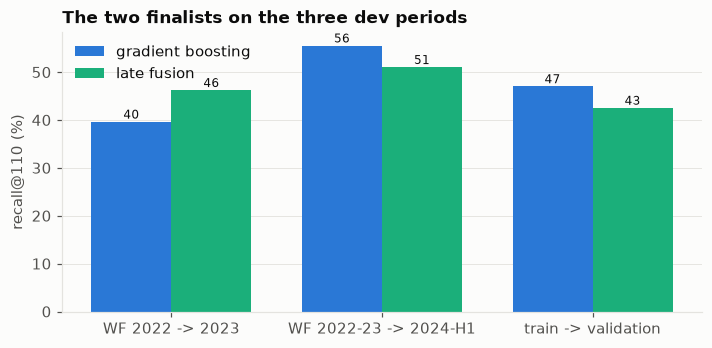

In [5]:
sd = T("05d_sensitivity_dev"); sd["model"] = sd["model"].str.replace(" (headline)", "", regex=False)
display(sd.set_index(["variant", "model"])[["wf_2023@110", "wf_2024h1@110", "val@110", "selection", "worst"]])
p = sd[sd["variant"] == "base (as in 05b)"].set_index("model")
fig, ax = plt.subplots(figsize=(7.5, 3.3)); x = np.arange(3); w = 0.38
for j, (m, c) in enumerate([("gradient boosting", BLUE), ("late fusion", AQUA)]):
    v = p.loc[m, ["wf_2023@110", "wf_2024h1@110", "val@110"]].astype(float).to_numpy(); ax.bar(x + (j - 0.5) * w, v, w, color=c, label=m)
    for xi, vi in zip(x, v): ax.annotate(f"{vi:.0f}", (xi + (j - 0.5) * w, vi), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=8)
ax.set_xticks(x, ["WF 2022 -> 2023", "WF 2022-23 -> 2024-H1", "train -> validation"]); ax.grid(axis="x", visible=False); ax.legend(frameon=False)
ax.set_ylabel("recall@110 (%)"); ax.set_title("The two finalists on the three dev periods", loc="left"); save(fig, "2_03_selection")

**Takeaway**: Gradient boosting and late fusion tie on dev (47.4 vs 46.7). Boosting was chosen as headline on **dev evidence only** — better on validation, robust to the uncertain-phrase check, simpler to deploy and explain — before the test set was opened; both were scored on test.